# Buckling of a CFRP stringer-stiffened cylinder under axial compression and torsion

Lanzi, Bisagni and Cordisco [1] designed cylinders of woven carbon fabric
stiffened by eight L-shaped stringers to work in the post-buckling range
under torsion, and analysed them with ABAQUS (shell elements S4R, a
geometrically nonlinear analysis with the Riks method or an explicit
dynamic analysis) in two configurations: A, with stringers only, and B,
with a central ring as well. Two specimens of configuration B were
manufactured and tested in torsion [1, 2, 3]; configuration A was analysed
only. For configuration A, [1] gives the first buckling load under axial
compression, 213 kN (Table 2), and the first buckling torque, 13.5 kNm
(Tables 3 and 4).

Here these two first buckling loads of configuration A are computed with a
linear buckling analysis of a model of discrete stringers:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- the L-shaped stringer assembled from two plates: the foot, a plate bonded
  on the inner surface of the skin, and the blade, a plate of BFSC plate
  elements `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d) rotated
  90 degrees on top of the foot, in the plane $(x, r)$, connected to the
  skin and the foot along their common edge;
- the reinforcing strips of the skin under the stringers as plates bonded
  on its outer surface.

The model is given by the module `composite_stiffened_shell.py`, next to
this notebook, also used in [First buckling of blade-stiffened CFRP curved
panels](abramovich2003_stiffened_panels.ipynb). Besides `bfsccylinder`, it
needs `bfscplate2d`, `composites`, `structsolve` and Matplotlib.

## Data of configuration A

All values in N and mm. Each value is given with the place where it was
read ([1] page numbers 75-2 to 75-5):

| quantity | value | source |
|---|---|---|
| $E_{11}$, $E_{22}$, $G_{12}$ | 57765, 53686, 3065 N/mm$^2$ | [1] Table 1; also [2] Table 1, [3] Table 1 |
| $\nu_{12}$ | 0.048 | [1] Table 1 |
| ply thickness | 0.330 mm | [1] Table 1 |
| free length $L$ | 540 mm (overall 700 mm with the two tabs) | [1] p. 75-2; [2] Section 2 |
| internal diameter | 700 mm | [1] p. 75-2 |
| skin | three layers $[45/0/-45]$, 0 along the axis | [1] p. 75-2; [3] p. 1808 |
| reinforced skin areas | 40 mm wide, on the outer surface, under the stringers, three layers added: $[-45/0/45]$ in [3], $[45/-45/45]$ in [1] | [1] p. 75-2; [3] p. 1808 |
| stringers | 8, L-shaped, equally spaced and equally oriented, bonded and riveted on the inner surface | [1] p. 75-2, 75-3 |
| L-section | blade 25 mm, part in contact with the skin (foot) 32 mm, corner of mean radius about 7 mm | [1] p. 75-2; [2] Table 2 ($25 \times 32$) |
| stringer lay-up | 8 plies, $[0/90]_{2S}$ | [2] Table 2 and p. 140, [3] p. 1808; see below |

The stringer lay-up is printed in [1] as "eight $[0°/90°]_{4S}$ oriented
layers", where eight layers and $[0/90]_{4S}$ (16 plies) disagree. [2]
(Table 2, third shell, the ring-stiffened shell tested in torsion, whose
stringers are "equal in number and dimensions to those of the first
configuration") and [3] (p. 1808) give eight plies $[0/90]_{2S}$, and the
nominal thicknesses of [2] Table 3 for that shell agree with three plies
of skin, three of reinforcement and eight of stringer, as computed below.
The model uses $[0/90]_{2S}$.

The reinforcement is $[45/-45/45]$ in [1] and $[-45/0/45]$ in [3] (for the
manufactured shells with ring). The model uses the $[-45/0/45]$ of [3],
which is balanced: the $[45/-45/45]$ of [1] has two $+45$ plies and one
$-45$, so that its extension-shear coupling stiffness $A_{16}$ is not zero.
The $[45/-45/45]$ of [1] is a variant below. The order in which
the plies of the skin and of the reinforcement are listed is taken from
the inner to the outer surface (the skin is not symmetric, so that the
order changes its coupling stiffnesses $\boldsymbol{B}$); the reversed order
of the skin is a variant below. TODO(author): is the stacking of [1] listed
from the inner surface of the skin? And are the reinforcements of 40 mm
centred on the 32 mm of the foot, as assumed below?

In [1]:
%matplotlib inline
import time

import numpy as np
from numpy import pi
import matplotlib.pyplot as plt
from composites import laminated_plate

from composite_stiffened_shell import (StiffenedShell, node_coordinates,
                                       plot_skin_w, DOF, U, V)

# [1] Table 1, N/mm^2 and mm; transverse shear moduli not used (Kirchhoff)
E11, E22, G12, nu12 = 57765., 53686., 3065., 0.048
laminaprop = (E11, E22, nu12, G12, G12, G12)
tp = 0.330
L = 540.
D_internal = 700.
nstringers = 8
skin_stack = [45, 0, -45]  # from the inner surface
strip_stack = [-45, 0, 45]  # [3]; from the skin outwards
stringer_stack = [0, 90, 0, 90, 90, 0, 90, 0]  # [0/90]_2S
blade_height = 25.  # outer dimension, from the inner surface of the skin
foot_width = 32.  # outer dimension, including the blade
strip_width = 40.

h_skin = len(skin_stack)*tp
t_strip = len(strip_stack)*tp
t_str = len(stringer_stack)*tp
R = D_internal/2 + h_skin/2  # mid-surface of the skin
pitch = 2*pi*R/nstringers
print('skin %.2f mm, reinforcement %.2f mm, stringer %.2f mm thick'
      % (h_skin, t_strip, t_str))
print('nominal skin + stringers: %.2f mm, [2] Table 3 (third shell): 4.62 mm'
      % (h_skin + t_strip + t_str))
print('R = %.3f mm, stringer pitch %.2f mm' % (R, pitch))

skin 0.99 mm, reinforcement 0.99 mm, stringer 2.64 mm thick
nominal skin + stringers: 4.62 mm, [2] Table 3 (third shell): 4.62 mm
R = 350.495 mm, stringer pitch 275.28 mm


## The model of a stringer

Over one pitch $2 \pi R/8$, the model has the plates:

- the **skin**, BFSC cylinder elements on the mid-surface of radius $R$ =
  350 + 0.99/2 mm;
- the **reinforcement**, a plate bonded on the outer surface of the skin,
  and the **foot**, a plate bonded on its inner surface: each is a laminate
  of BFSC cylinder elements on the nodes of the skin, whose stiffness
  matrices $\boldsymbol{A}$, $\boldsymbol{B}$, $\boldsymbol{D}$ are
  referred to the mid-surface of the skin through the offset of its plies,
  $\pm (h_{skin} + t)/2$ (a perfect bond, the plates sharing the normal of
  the Kirchhoff hypothesis); the stiffnesses of the plates add up. A flat
  plate element does not fit the curved surface of the skin (the foot spans
  5 degrees of arc), hence the cylinder element;
- the **blade**, a plate of BFSC plate elements in the plane $(x, r)$,
  rotated 90 degrees on top of the foot at its edge, from the mid-surface of
  the skin to the tip, of height $25 + h_{skin}/2$, whose root has the
  translations and the rotation about $x$ of the skin and foot along their
  common edge (see the docstring of the module).

The outer dimensions of the L, 25 and 32 mm, are taken from the inner
surface of the skin and from the outer face of the blade; the foot of the
model spans $32 - t/2$ from the mid-plane of the blade. The corner of radius
7 mm and the rivets are not modelled, and the blade plate overlaps the skin
and the foot over its first $h_{skin}/2 + t$ = 3.1 mm, which adds 8 mm$^2$
to the 67 mm$^2$ of the blade. The plot shows one stringer over the
developed section (radial dimensions magnified):

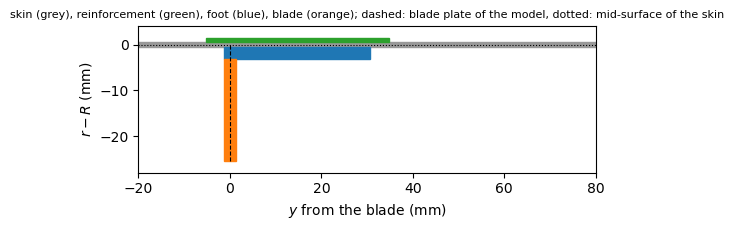

In [2]:
skin = laminated_plate(skin_stack, plyt=tp, laminaprop=laminaprop)
foot = laminated_plate(stringer_stack, plyt=tp, laminaprop=laminaprop,
                       offset=-(h_skin/2 + t_str/2))
blade = laminated_plate(stringer_stack, plyt=tp, laminaprop=laminaprop)
foot_model = foot_width - t_str/2  # from the mid-plane of the blade
# reinforcement centred on the footprint of the L, of foot_width
s_before = (strip_width - foot_width)/2 + t_str/2
s_after = (strip_width - foot_width)/2


def strip_laminate(stack):
    return laminated_plate(stack, plyt=tp, laminaprop=laminaprop,
                           offset=h_skin/2 + len(stack)*tp/2)


def build(nbay, nfoot, nx, nh, skin_lam=skin, strip_lam=None,
          bottom_rotation_free=False):
    strip_lam = strip_laminate(strip_stack) if strip_lam is None else strip_lam
    segments = []
    for k in range(nstringers):
        segments += [(s_before, 1), (foot_model, nfoot), (s_after, 1),
                     (pitch - strip_width, nbay)]
    y = node_coordinates(segments)
    model = StiffenedShell(R, L, y, True, nx, skin_lam)
    for k in range(nstringers):
        y0 = k*pitch
        model.add_plate(strip_lam, y0, y0 + strip_width)
        model.add_plate(foot, y0 + s_before, y0 + s_before + foot_model)
        model.add_blade(y0 + s_before, blade_height + h_skin/2, blade, nh,
                        'internal')
    model.build()
    model.clamp_end(0, rotation_free=bottom_rotation_free)
    mu, mv = model.rigid_end(-1)
    return model, mu, mv


fig, ax = plt.subplots(figsize=(8, 2.4))
ax.add_patch(plt.Rectangle((-20, -h_skin/2), 100, h_skin, color='0.6'))
ax.add_patch(plt.Rectangle((-s_before, h_skin/2), strip_width, t_strip,
                           color='tab:green'))
ax.add_patch(plt.Rectangle((-t_str/2, -h_skin/2 - t_str), foot_width,
                           t_str, color='tab:blue'))
ax.add_patch(plt.Rectangle((-t_str/2, -h_skin/2 - blade_height), t_str,
                           blade_height - t_str, color='tab:orange'))
ax.plot([0, 0], [0, -h_skin/2 - blade_height], 'k--', lw=0.8)
ax.plot([-20, 80], [0, 0], 'k:', lw=0.8)
ax.set_xlim(-20, 80)
ax.set_ylim(-28, 4)
ax.set_aspect('equal')
ax.set_xlabel('$y$ from the blade (mm)')
ax.set_ylabel('$r - R$ (mm)')
ax.set_title('skin (grey), reinforcement (green), foot (blue), blade '
             '(orange); dashed: blade plate of the model, dotted: '
             'mid-surface of the skin', fontsize=8)
plt.tight_layout()
plt.show()

## Boundary conditions, loads and analysis

In the tests the cylinder is clamped by its tabs between two loading
platforms [1, 3]; in the analyses of [1] the translations of the lower
edge are fixed and the upper edge is attached to a rigid body to which the
displacement is applied. The model has:

- the edge $x = 0$ clamped: $u = v = w = w_{,x} = 0$ for the skin and the
  plates on it, $U = V = W = W_{,X} = 0$ for the blades (the variant
  "rotation free at $x = 0$" below leaves $w_{,x}$ and $W_{,X}$ free, the
  lower edge of the analyses of [1]);
- the edge $x = L$ attached to a rigid ring: $w = w_{,x} = 0$, a uniform
  axial displacement $u = U$ and a rotation $\phi$ about the axis, $v =
  R \phi$ for the skin and $W = (R + Y)\phi$, $W_{,Y} = \phi$, $V = 0$ for
  the blades (`StiffenedShell.rigid_end`). The axial force $P$ and the
  torque $T$ are applied to the ring, the torque as the force $T/R$ on the
  degree of freedom $R\phi$, a shear load on the end of the cylinder
  that keeps its section circular.

As in all the models of `bfsccylinder`, the derivatives along an edge of
the displacements prescribed on it are prescribed as well: $u_{,y} =
v_{,y} = w_{,y} = w_{,xy} = 0$ for the skin and $U_{,Y} = V_{,Y} = W_{,Y}
= W_{,XY} = 0$ for the blades at $x = 0$ ($w_{,xy}$ and $W_{,XY}$ free,
with $w_{,x}$ and $W_{,X}$, in the variant with the rotation free), and at the ring, where $u$, $v$ and $w$ are uniform,
$u_{,y} = v_{,y} = w_{,y} = w_{,xy} = 0$, with $W_{,Y} = \phi$ for the
blades.

The load cases are:

- **axial compression**, [1] Table 2: the force $P$ on the ring, $\phi =
  0$;
- **torsion with free axial shortening**, [1] Table 3: the torque $T$, the
  axial displacement of the ring free;
- **torsion with constrained axial shortening**, [1] Table 4: the torque
  $T$, the axial displacement of the ring zero.

The pre-buckling state is the linear static solution $\boldsymbol{u}_0$ of
$\boldsymbol{K}_{C0} \boldsymbol{u}_0 = \boldsymbol{F}$ for the unit load,
and the geometric stiffness matrix $\boldsymbol{K}_G$ of the membrane
forces of $\boldsymbol{u}_0$ (with the in-plane terms of the blades) gives
the linear buckling problem

$$(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)\boldsymbol{\phi} =
\boldsymbol{0}$$

solved with `structsolve.lb`; see [Analyses](../analyses.rst). The
shear flow of torsion, $N_{xy} = T/(2 \pi R^2)$ in the skin, enters
$\boldsymbol{K}_G$ through the term $2 N_{xy} w_{,x} w_{,y}$, whose sign
follows that of $T$: the skin, the reinforcement and the L-sections, all
equally oriented, are not symmetric about any plane through the axis, so
that the critical torques of the two senses of rotation differ; both are
computed, $T > 0$ turning the ring towards $+y$ and $T < 0$ with the load
reversed. The stiffnesses $P/\delta$ and $T/\phi$ of the pre-buckling state
are compared with those of [1].

**Why the whole cylinder.** The L-sections and the laminates are not
symmetric about any plane through the axis, so that no plane of symmetry
can be used. A sector of one stringer pitch with periodic conditions
represents only the modes in which all eight bays deform in the same way,
whereas the local modes of the skin between the stringers form a cluster
of eight close eigenvalues, one for each harmonic of the cyclic symmetry,
as seen below; the whole cylinder gives all of them.

In [3]:
def analyse(mesh, case, reverse=False, num_eigvalues=12, **kw):
    t0 = time.time()
    model, mu, mv = build(*mesh, **kw)
    if case == 'axial':
        model.fixed.add(mv)
        load = {mu: -1.}  # P = 1 N, compression
    elif case == 'torsion':
        load = {mv: 1./R}  # T = 1 N mm
    elif case == 'torsion constrained':
        model.fixed.add(mu)
        load = {mv: 1./R}
    model.finalize()
    lam, modes, u0 = model.buckling(load, num_eigvalues=num_eigvalues,
                                    reverse=reverse)
    out = dict(model=model, lam=lam, modes=modes, dofs=model.Nr,
               time=time.time() - t0)
    if case == 'axial':
        out['Pcr'] = lam/1e3  # kN
        out['stiffness'] = 1./(-u0[mu])/1e3  # kN/mm
        out['shortening'] = lam[0]*(-u0[mu])  # mm at buckling
    else:
        out['Tcr'] = lam/1e6  # kNm
        phi = np.degrees(u0[mv]/R)
        out['stiffness'] = 1e-6/phi  # kNm/degree
        out['rotation'] = lam[0]*phi  # degree at buckling
    return out

## Mesh convergence

Meshes of `nbay` elements between two reinforcements, `nfoot` elements
across the foot, `nx` nodes along $x$ and `nh` elements along the height
of a blade; the 4 and 5.3 mm of reinforcement on both sides of the foot
have one element each. The fourth mesh is the finest, to show that the
third one is converged (it takes about half an hour):

In [4]:
meshes = [(6, 2, 19, 2), (10, 2, 28, 3), (14, 3, 37, 3), (20, 3, 55, 4)]
conv = {}
for mesh in meshes:
    conv[mesh] = {}
    for case in ('axial', 'torsion'):
        r = analyse(mesh, case)
        conv[mesh][case] = r
        first = r['Pcr'][0] if case == 'axial' else r['Tcr'][0]
        print('mesh %-15s %6d dofs, %-8s: %s = %.2f %s, %.0f s'
              % (mesh, r['dofs'], case,
                 'P_cr' if case == 'axial' else 'T_cr', first,
                 'kN' if case == 'axial' else 'kNm', r['time']))
print()
for m0, m1 in zip(meshes[:-1], meshes[1:]):
    dP = conv[m1]['axial']['Pcr'][0]/conv[m0]['axial']['Pcr'][0] - 1
    dT = conv[m1]['torsion']['Tcr'][0]/conv[m0]['torsion']['Tcr'][0] - 1
    print('%s -> %s: P_cr %+.2f %%, T_cr %+.2f %%'
          % (m0, m1, 100*dP, 100*dT))

mesh (6, 2, 19, 2)    17009 dofs, axial   : P_cr = 254.56 kN, 32 s


mesh (6, 2, 19, 2)    17010 dofs, torsion : T_cr = 18.33 kNm, 18 s


mesh (10, 2, 28, 3)   36353 dofs, axial   : P_cr = 253.74 kN, 137 s


mesh (10, 2, 28, 3)   36354 dofs, torsion : T_cr = 17.83 kNm, 55 s


mesh (14, 3, 37, 3)   62897 dofs, axial   : P_cr = 252.43 kN, 313 s


mesh (14, 3, 37, 3)   62898 dofs, torsion : T_cr = 17.76 kNm, 131 s


mesh (20, 3, 55, 4)  124769 dofs, axial   : P_cr = 251.99 kN, 636 s


mesh (20, 3, 55, 4)  124770 dofs, torsion : T_cr = 17.74 kNm, 352 s

(6, 2, 19, 2) -> (10, 2, 28, 3): P_cr -0.32 %, T_cr -2.77 %
(10, 2, 28, 3) -> (14, 3, 37, 3): P_cr -0.52 %, T_cr -0.35 %
(14, 3, 37, 3) -> (20, 3, 55, 4): P_cr -0.17 %, T_cr -0.12 %


From the second to the third mesh the first buckling load changes by
$-0.52$ % and the first buckling torque by $-0.35$ %, and from the third
to the fourth mesh, `(20, 3, 55, 4)` with 124769 degrees of freedom, by
$-0.17$ % and $-0.12$ %; the third mesh, `(14, 3, 37, 3)`, with elements
of about 17 by 15 mm between the reinforcements, is used below.

In [5]:
mesh = (14, 3, 37, 3)
res = {
    'axial': conv[mesh]['axial'],
    'torsion': conv[mesh]['torsion'],
    'torsion reversed': analyse(mesh, 'torsion', reverse=True),
    'torsion constrained': analyse(mesh, 'torsion constrained'),
}
for k, r in res.items():
    vals = r['Pcr'] if k == 'axial' else r['Tcr']
    print('%-20s %s' % (k, np.array2string(vals, precision=2)))

axial                [252.43 252.43 252.43 252.44 252.44 252.45 252.45 252.45 252.57 252.57
 252.57 252.58]
torsion              [17.76 17.85 17.85 18.07 18.08 18.08 18.19 18.19 18.38 18.38 18.5  18.5 ]
torsion reversed     [17.85 17.93 17.93 18.16 18.16 18.16 18.28 18.28 18.46 18.46 18.59 18.59]
torsion constrained  [17.76 17.85 17.85 18.07 18.08 18.08 18.19 18.19 18.38 18.38 18.49 18.49]


## Pre-buckling stiffnesses

Two estimates check the stiffnesses of the model: the axial stiffness of
the bar of the laminates, $\sum_i b_i A_{11,i}/L$ over the widths $b_i$
of the plates of the section, without (upper value) and with the free
lateral contraction, $A_{11} - A_{12}^2/A_{22}$; and the torsional
stiffness of the thin-walled closed section, $4 \mathcal{A}^2/(L \oint
ds/A_{66})$, with $\mathcal{A} = \pi R^2$ and $A_{66}$ of the skin, plus
reinforcement and foot under the stringers.

In [6]:
strip = strip_laminate(strip_stack)
bars = [(2*pi*R, skin), (nstringers*strip_width, strip),
        (nstringers*foot_model, foot),
        (nstringers*(blade_height + h_skin/2), blade)]
EA = sum(b*lam.A11 for b, lam in bars)
EA_free = sum(b*(lam.A11 - lam.A12**2/lam.A22) for b, lam in bars)
under_foot = foot_model
under_strip = strip_width - foot_model
rest = 2*pi*R - nstringers*strip_width
ds_A66 = (rest/skin.A66
          + nstringers*under_strip/(skin.A66 + strip.A66)
          + nstringers*under_foot/(skin.A66 + strip.A66 + foot.A66))
GJ = 4*(pi*R**2)**2/ds_A66
print('axial: model %.1f kN/mm; bar estimate %.1f (free contraction %.1f) '
      'kN/mm; [1] Table 2: 215 kN/mm'
      % (res['axial']['stiffness'], EA/L/1e3, EA_free/L/1e3))
print('torsion: model %.1f kNm/degree; thin-walled estimate %.1f kNm/degree;'
      ' [1] Table 3: 15.8 kNm/degree'
      % (res['torsion']['stiffness'], GJ/L*pi/180/1e6))

axial: model 275.3 kN/mm; bar estimate 311.4 (free contraction 271.9) kN/mm; [1] Table 2: 215 kN/mm
torsion: model 178.9 kNm/degree; thin-walled estimate 177.2 kNm/degree; [1] Table 3: 15.8 kNm/degree


The axial stiffness of the model lies between the two bar estimates, 1.3 %
above the one with free lateral contraction (the large Poisson's ratio of
the $\pm 45$ plies makes the difference); the torsional stiffness is 1.0 %
above the thin-walled estimate. Both are above those of [1]: 215 kN/mm,
[1] Table 2, is 78 % of the axial stiffness of the model, and the slope of
the torque-rotation curve of [1] Fig. 4, about 161 kNm/degree, is 90 % of
the torsional stiffness. The 15.8 kNm/degree printed in [1] Tables 3 and 4
is a tenth of that slope and of the pre-buckling stiffnesses measured on
the two shells of configuration B, 153 and 159 kNm/degree ([1] Table 5,
p. 75-11; 158 kNm/degree in [2] p. 148). The data of [1-3] do not explain
the difference: a stringer of 16 plies, the $[0/90]_{4S}$ as printed in
[1], would make the model stiffer still.

## Comparison with Lanzi, Bisagni and Cordisco [1]

The first buckling loads of [1] are those of geometrically nonlinear
analyses of the perfect shell: the load at which the first buckles appear
and the load-shortening (torque-rotation) curve drops, [1] Figs. 2 and 4.
Besides the values of the tables, the curves of Figs. 2 and 4 were read
(pixel coordinates of the PDF page rendered at 500 and 600 dpi, precision about
$\pm 2$ kN, $\pm 0.01$ mm, $\pm 0.3$ kNm and $\pm 0.005$ degree): the
curves labelled "without reinforcing ring" have their first peak at about
198 kN and 0.91 mm (axial) and 14.2 kNm and 0.088 degree (torsion, free
axial displacement), whereas the curve labelled "with reinforcing ring" of
Fig. 2 has its first peak at about 213 kN and 0.98 mm. Since the strain
of the skin at buckling hardly depends on the stringers, the shortening
and the rotation at first buckling are compared as well.

In [7]:
ra, rt = res['axial'], res['torsion']
rows = [
    ('P_cr, axial (kN)', ra['Pcr'][0], [('[1] Table 2', 213.),
                                        ('[1] Fig. 2, first peak', 198.)]),
    ('shortening at P_cr (mm)', ra['shortening'],
     [('[1] Table 2: 213/215', 213./215.), ('[1] Fig. 2', 0.91)]),
    ('P/delta (kN/mm)', ra['stiffness'], [('[1] Table 2', 215.)]),
    ('T_cr, T > 0, free shortening (kNm)', rt['Tcr'][0],
     [('[1] Table 3', 13.5), ('[1] Fig. 4, first peak', 14.2)]),
    ('T_cr, T < 0, free shortening (kNm)', res['torsion reversed']['Tcr'][0],
     [('[1] Table 3', 13.5)]),
    ('T_cr, T > 0, constrained shortening (kNm)',
     res['torsion constrained']['Tcr'][0], [('[1] Table 4', 13.5)]),
    ('rotation at T_cr (degree)', rt['rotation'],
     [('[1] Fig. 4', 0.088)]),
    ('T/phi (kNm/degree)', rt['stiffness'], [('[1] Table 3', 15.8),
                                             ('[1] Fig. 4: 14.2/0.088',
                                              14.2/0.088)]),
]
print('%-42s %8s | %-26s %8s %9s' % ('quantity', 'present', 'reference',
                                     'value', 'rel. diff.'))
for name, val, refs in rows:
    for i, (rname, rval) in enumerate(refs):
        head = '%-42s %8.3g' % (name, val) if i == 0 else ' '*51
        print('%s | %-26s %8.3g %+8.1f %%'
              % (head, rname, rval, 100*(val - rval)/rval))

quantity                                    present | reference                     value rel. diff.
P_cr, axial (kN)                                252 | [1] Table 2                     213    +18.5 %
                                                    | [1] Fig. 2, first peak          198    +27.5 %
shortening at P_cr (mm)                       0.917 | [1] Table 2: 213/215          0.991     -7.5 %
                                                    | [1] Fig. 2                     0.91     +0.7 %
P/delta (kN/mm)                                 275 | [1] Table 2                     215    +28.1 %
T_cr, T > 0, free shortening (kNm)             17.8 | [1] Table 3                    13.5    +31.6 %
                                                    | [1] Fig. 4, first peak         14.2    +25.1 %
T_cr, T < 0, free shortening (kNm)             17.9 | [1] Table 3                    13.5    +32.2 %
T_cr, T > 0, constrained shortening (kNm)      17.8 | [1] Table 4                    13.5  

## Buckling modes

The normal displacement $w$ of the skin of the first modes, over the
developed cylinder seen from the outside, with the blades as lines; the
foot of each stringer extends towards $+y$ from its blade:

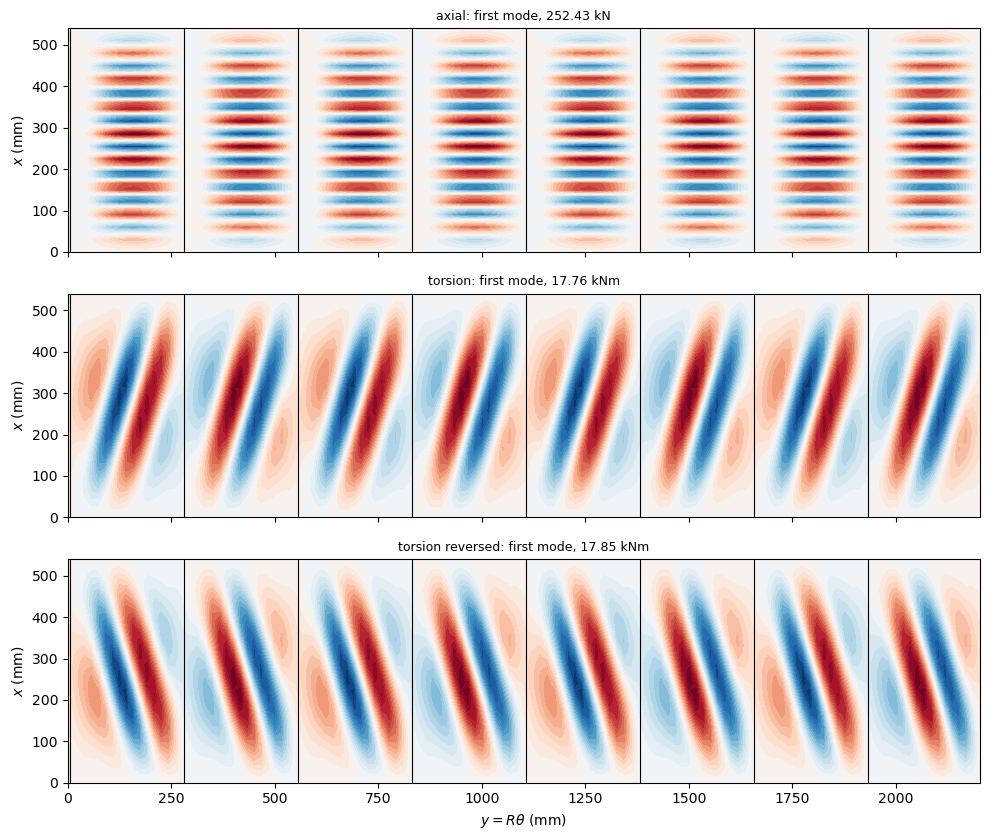

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
for ax, key in zip(axes, ['axial', 'torsion', 'torsion reversed']):
    r = res[key]
    val = (r['Pcr'][0], 'kN') if key == 'axial' else (r['Tcr'][0], 'kNm')
    plot_skin_w(ax, r['model'], r['modes'][:, 0],
                '%s: first mode, %.2f %s' % (key, *val))
    ax.set_ylabel('$x$ (mm)')
    ax.set_xlabel('')
axes[-1].set_xlabel(r'$y = R\theta$ (mm)')
plt.tight_layout()
plt.show()

## Variants of the data

The same mesh with one change at a time: the plies of the skin listed from
the outer surface, $[-45/0/45]$ from the inner one; the reinforcement
$[45/-45/45]$ of [1]; and the lower edge with the rotations free, as in the
analyses of [1]:

In [9]:
variants = {
    'skin [-45/0/45] from inside': dict(
        skin_lam=laminated_plate(skin_stack[::-1], plyt=tp,
                                 laminaprop=laminaprop)),
    'reinforcement [45/-45/45] [1]': dict(
        strip_lam=strip_laminate([45, -45, 45])),
    'rotation free at x = 0': dict(bottom_rotation_free=True),
}
print('%-30s %10s %14s %14s' % ('variant', 'P_cr (kN)', 'T_cr T>0 (kNm)',
                                'T_cr T<0 (kNm)'))
print('%-30s %10.1f %14.2f %14.2f' % ('reference model', ra['Pcr'][0],
                                      rt['Tcr'][0],
                                      res['torsion reversed']['Tcr'][0]))
for name, kw in variants.items():
    a = analyse(mesh, 'axial', **kw)
    tp_ = analyse(mesh, 'torsion', **kw)
    tm = analyse(mesh, 'torsion', reverse=True, **kw)
    print('%-30s %10.1f %14.2f %14.2f'
          % (name, a['Pcr'][0], tp_['Tcr'][0], tm['Tcr'][0]))

variant                         P_cr (kN) T_cr T>0 (kNm) T_cr T<0 (kNm)
reference model                     252.4          17.76          17.85


skin [-45/0/45] from inside         252.4          17.85          17.76


reinforcement [45/-45/45] [1]       242.9          17.69          17.78


rotation free at x = 0              244.4          17.69          17.81


## Discussion

**Axial compression.** The first mode is a local mode of the skin between
the reinforcements, with short axial half-waves, about 18 along the
length, across the whole width of each bay; the twelve lowest loads are
within 0.06 % of each other, one for each combination of the eight bays.
The first buckling load of the model, 252.4 kN, is 18.5 % above the value
of [1] Table 2 and 27.5 % above the first peak of the curve of [1] Fig. 2
labelled "without reinforcing ring", but the shortening at first
buckling, 0.917 mm, is within 1 % of that peak (0.91 mm) and 7.5 % below
213/215 = 0.99 mm: the skin buckles at almost the same strain, and the
difference of the loads follows that of the axial stiffnesses, 275 kN/mm
here and 215 kN/mm in [1] (see above). The rotations free at the lower
edge, as in the analyses of [1], lower the first buckling load by 3.2 %,
and the unbalanced reinforcement $[45/-45/45]$ of [1] by 3.8 %, to 242.9
kN, 14.0 % above [1] Table 2. The values of [1] are first buckling loads
of geometrically nonlinear analyses of the perfect shell, which follow
the bending of the stringers, whose cross-sections are not symmetric
about the skin, and the deformation near the ends before buckling; the
linear buckling analysis about the linear pre-buckling state does not.

**Torsion.** The first mode has, in each bay, two main buckles of opposite
sign, inclined like the diagonal of the bay that goes from the lower edge
towards $+y$ at the upper edge for $T > 0$, and like the other diagonal
for $T < 0$; the twelve lowest torques are within 5 %. The first buckling
torque, 17.76 kNm, is 31.6 % above the 13.5 kNm of [1] Tables 3 and 4 and
25.1 % above the first peak of [1] Fig. 4, and the rotation at first
buckling, 0.099 degree, is 13 % above the 0.088 degree of that peak: in
torsion too the model is stiffer (11 % above the slope of Fig. 4) and
buckles at a larger shear strain. As in [1], free and constrained axial
shortening give the same first buckling torque (here to 0.01 kNm). The
two senses of rotation differ by 0.5 %; listing the plies of the skin in
the reversed order swaps the two values, so that the difference comes
from the coupling stiffnesses $\boldsymbol{B}$ of the unsymmetric skin,
not from the orientation of the L-sections. The reinforcement of [1]
changes the first buckling torque by $-0.4$ %.

**Data.** The differences with [1] are not explained by the variants
computed here (at most 4 %): the stacking direction of the skin, the
lay-up of the reinforcement and the rotation at the lower edge. The model
leaves out the corner of radius 7 mm of the L-sections and the rivets,
and uses the nominal thicknesses (the measured skin of the shell with
ring, 1.090 mm against 0.99 mm nominal, [2] Table 3, would raise the
buckling loads).

**Suspected errors in [1].** This case is kept as a documented
discrepancy: the model is not adjusted to [1], three of whose data are
probably wrong.

- The model of [1] is more flexible than the published data imply: its
  axial stiffness, 215 kN/mm ([1] Table 2), and the slope of its
  torque-rotation curve, about 161 kNm/degree ([1] Fig. 4), are 22 % and
  10 % below those of the present model, which agree within 1.3 % with
  the estimates from the nominal section and laminates (see above); its
  first buckling load under axial compression is lower too, at almost
  the same shortening.
- The torsional stiffness of 15.8 kNm/degree of [1] Tables 3 and 4 is a
  tenth of the slope of [1] Fig. 4, of the 153 and 159 kNm/degree measured
  ([1] Table 5) and of the 158 kNm/degree of [2] (p. 148): probably a
  misprint of 158 kNm/degree.
- The labels of the two curves of [1] Fig. 2 are possibly swapped with
  respect to [1] Table 2: the curve labelled "without reinforcing ring"
  has its first peak at about 198 kN, the one labelled "with reinforcing
  ring" at about 213 kN and 0.98 mm, whereas Table 2 gives 213 kN without
  and 217 kN with the ring. With the labels swapped, the shortening at
  first buckling of configuration A is 0.98 mm, and that of the model,
  0.917 mm, is 6.4 % below it.

**The panels implementation.** The panels implementation of this case
([panels](https://github.com/saullocastro/panels), notebook
`lanzi2003_torsion_cylinder`, values of 2026-11-04, with the
reinforcement $[45/-45/45]$ of [1]) agrees with the present one: it gives
230.1 kN and 17.58 kNm, against 242.9 kN and 17.69 kNm of the present
model with the same reinforcement (variant above), and its pre-buckling
stiffnesses, 260.1 kN/mm and 180.8 kNm/degree, are also above those of
[1]; the reinforcement $[-45/0/45]$ raises its loads by 4.7 % (axial) and
0.4 % (torsion). The two implementations are 8 to 19 % above [1] under
axial compression and 30 to 32 % above [1] in torsion.

## References

[1] Lanzi, L., Bisagni, C. and Cordisco, P., "Post-buckling design and
testing of composite stiffened cylindrical shells under torsion", 29th
European Rotorcraft Forum, Friedrichshafen, Germany, 16-18 September 2003,
paper 75. http://hdl.handle.net/20.500.11881/394

[2] Bisagni, C. and Cordisco, P., "Post-buckling and collapse experiments
of stiffened composite cylindrical shells subjected to axial loading and
torque", Composite Structures, 73(2), 138-149, 2006.
https://doi.org/10.1016/j.compstruct.2005.11.055

[3] Bisagni, C. and Cordisco, P., "Testing of stiffened composite
cylindrical shells in the postbuckling range until failure", AIAA Journal,
42(9), 1806-1817, 2004. https://doi.org/10.2514/1.6088